In [1]:
!pip install kagglehub

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("gokulrajkmv/unemployment-in-india")

print("Path to dataset files:", path)

100%|██████████| 16.0k/16.0k [00:00<00:00, 8.81MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/gokulrajkmv/unemployment-in-india/versions/5


In [3]:
import pandas as pd
import os

# 1. Automatically target the downloaded CSV file inside the kagglehub folder
csv_file_path = os.path.join(path, "Unemployment in India.csv")
df = pd.read_csv(csv_file_path)

# 2. Strip accidental blank spaces out of column names
df.columns = df.columns.str.strip()

# 3. Drop completely blank rows
df.dropna(inplace=True)

# 4. Convert the Date string text into an active Datetime object
df['Date'] = pd.to_datetime(df['Date'].str.strip(), format='%d-%m-%Y')

# 5. Extract month names for our future trend analysis
df['Month'] = df['Date'].dt.strftime('%B')

print("Data loaded successfully!")
print(df.head())

Data loaded successfully!
           Region       Date Frequency  Estimated Unemployment Rate (%)  \
0  Andhra Pradesh 2019-05-31   Monthly                             3.65   
1  Andhra Pradesh 2019-06-30   Monthly                             3.05   
2  Andhra Pradesh 2019-07-31   Monthly                             3.75   
3  Andhra Pradesh 2019-08-31   Monthly                             3.32   
4  Andhra Pradesh 2019-09-30   Monthly                             5.17   

   Estimated Employed  Estimated Labour Participation Rate (%)   Area  \
0          11999139.0                                    43.24  Rural   
1          11755881.0                                    42.05  Rural   
2          12086707.0                                    43.50  Rural   
3          12285693.0                                    43.97  Rural   
4          12256762.0                                    44.68  Rural   

       Month  
0        May  
1       June  
2       July  
3     August  
4  Septem

/tmp/ipykernel_1438/1149869065.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Area', y='Estimated Unemployment Rate (%)', data=df, palette='Set2')


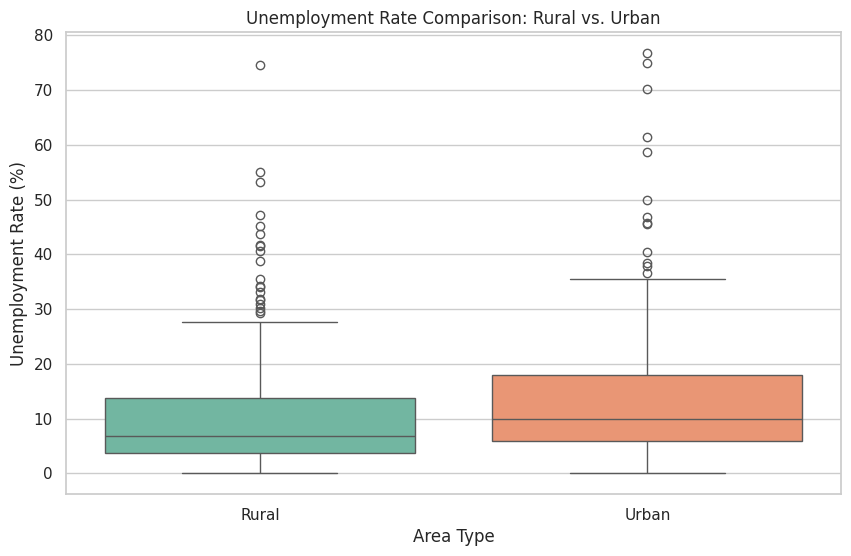

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for the plots
sns.set_theme(style="whitegrid")

# Create the Boxplot comparing Rural and Urban sectors
plt.figure(figsize=(10, 6))
sns.boxplot(x='Area', y='Estimated Unemployment Rate (%)', data=df, palette='Set2')

plt.title('Unemployment Rate Comparison: Rural vs. Urban')
plt.ylabel('Unemployment Rate (%)')
plt.xlabel('Area Type')
plt.show()

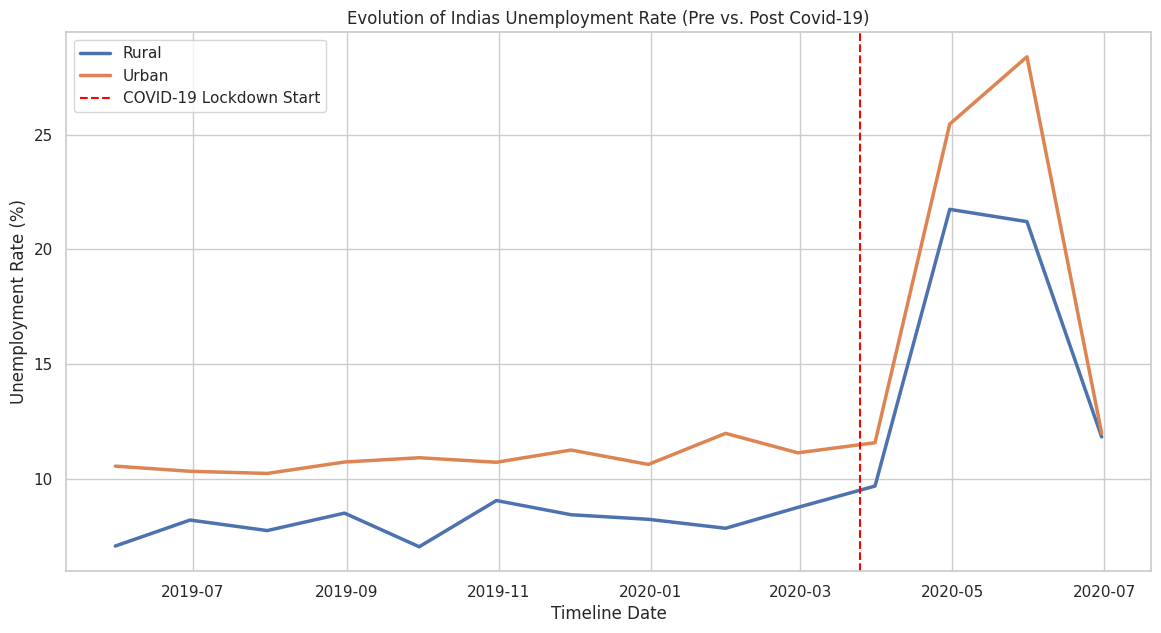

In [5]:
plt.figure(figsize=(14, 7))

# Create a line plot tracking changes over time
sns.lineplot(data=df, x='Date', y='Estimated Unemployment Rate (%)', hue='Area', errorbar=None, linewidth=2.5)

# Draw a vertical reference line showing exactly when lockdown started
plt.axvline(pd.to_datetime('2020-03-25'), color='red', linestyle='--', label='COVID-19 Lockdown Start')

plt.title('Evolution of Indias Unemployment Rate (Pre vs. Post Covid-19)')
plt.ylabel('Unemployment Rate (%)')
plt.xlabel('Timeline Date')
plt.legend()
plt.show()

/tmp/ipykernel_1438/3298165028.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Estimated Unemployment Rate (%)', y='Region', data=state_impact, palette='coolwarm')


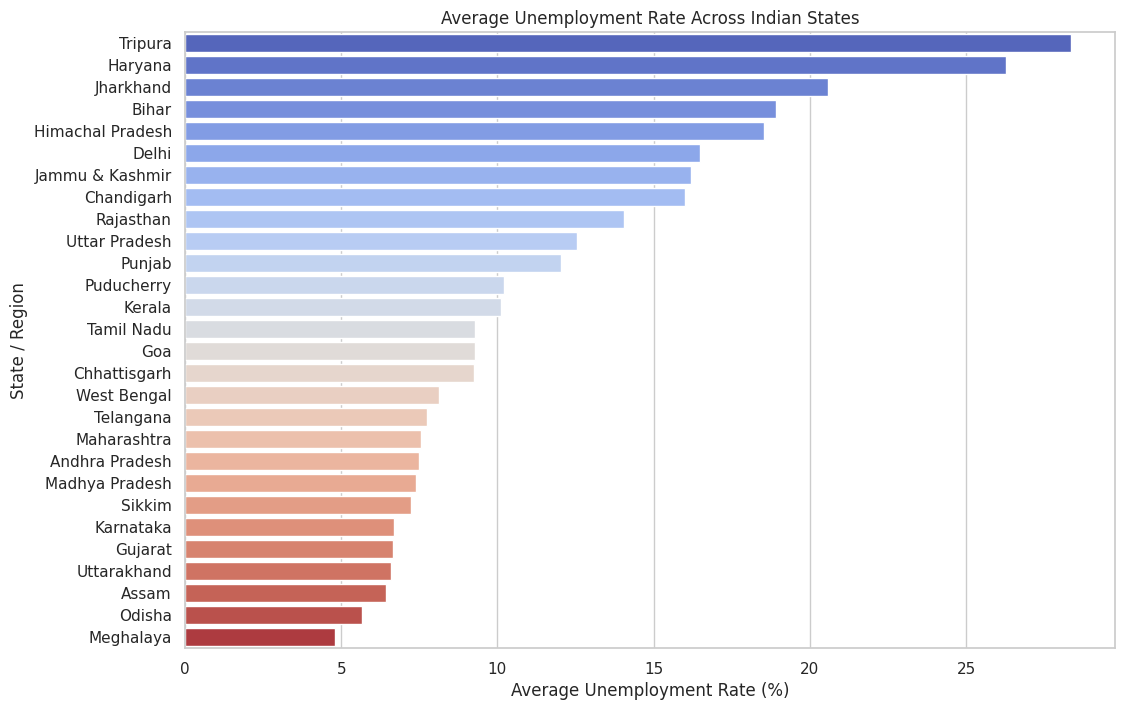

In [6]:
# Group data by State and calculate the average rates
state_impact = df.groupby('Region')['Estimated Unemployment Rate (%)'].mean().reset_index()
state_impact = state_impact.sort_values(by='Estimated Unemployment Rate (%)', ascending=False)

# Plot the horizontal ranking chart
plt.figure(figsize=(12, 8))
sns.barplot(x='Estimated Unemployment Rate (%)', y='Region', data=state_impact, palette='coolwarm')

plt.title('Average Unemployment Rate Across Indian States')
plt.xlabel('Average Unemployment Rate (%)')
plt.ylabel('State / Region')
plt.show()

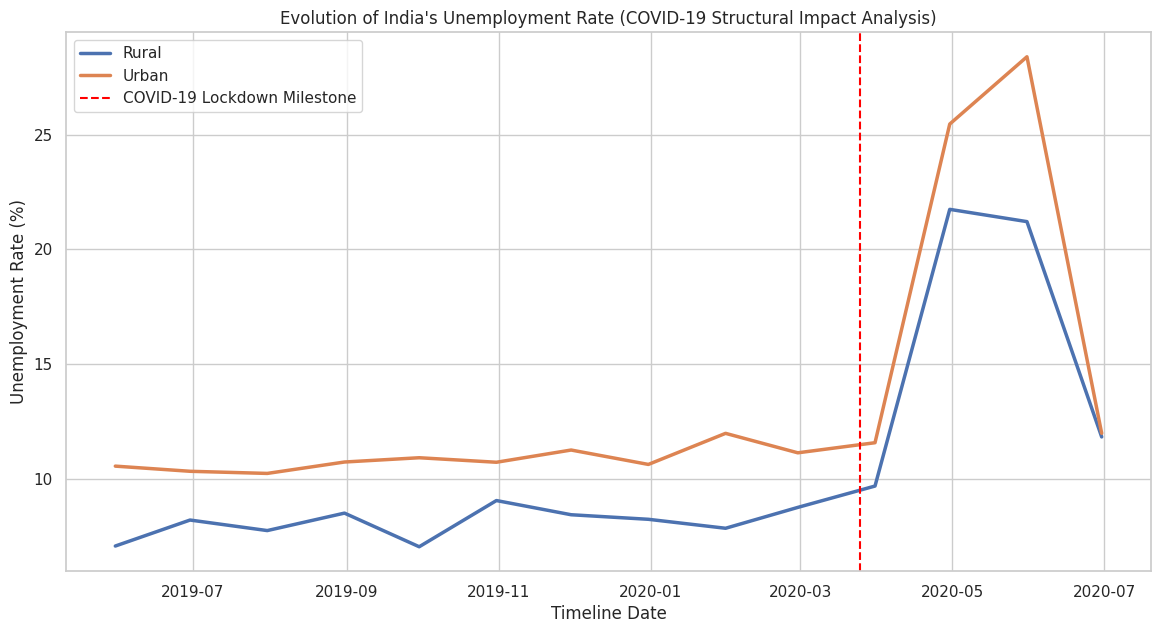

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set a larger canvas size to stretch the timeline properly
plt.figure(figsize=(14, 7))

# Line plot tracking the monthly metrics, split dynamically by Area (Rural vs Urban)
sns.lineplot(data=df, x='Date', y='Estimated Unemployment Rate (%)', hue='Area', errorbar=None, linewidth=2.5)

# Draw a distinct red dashed marker to show exactly when the national lockdown started
plt.axvline(pd.to_datetime('2020-03-25'), color='red', linestyle='--', label='COVID-19 Lockdown Milestone')

plt.title('Evolution of India\'s Unemployment Rate (COVID-19 Structural Impact Analysis)')
plt.ylabel('Unemployment Rate (%)')
plt.xlabel('Timeline Date')
plt.legend()
plt.show()